<a href="https://colab.research.google.com/github/amnisymimi/sign-language-translation/blob/nuhaa-dev/features/nonmanual/P2_Facial_Feature_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Extract Facial Features

In [ ]:
!pip install mediapipe opencv-python-headless numpy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 MB 18.7 MB/s  0:00:02
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]


In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import urllib.request

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.14.0
MediaPipe: 1.2.0
NumPy: 2.4.6


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 감정표현 수화 Expression of one's feelings KSL (korean sign language).mp4 to 감정표현 수화 Expression of one's feelings KSL (korean sign language).mp4


In [ ]:
video_path = list(uploaded.keys())[0]

print("Video uploaded:", video_path)

Video uploaded: 감정표현 수화 Expression of one's feelings KSL (korean sign language).mp4


In [ ]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

duration = total_frames / fps if fps > 0 else 0

print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration:", duration, "seconds")

cap.release()

FPS: 29.97002997002997
Total frames: 7586
Duration: 253.11953333333335 seconds


In [ ]:
model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/latest/"
    "face_landmarker.task"
)

model_path = "face_landmarker.task"

urllib.request.urlretrieve(model_url, model_path)

print("Face Landmarker model downloaded!")

Face Landmarker model downloaded!


In [ ]:
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=RunningMode.VIDEO,
    output_face_blendshapes=True,
    output_facial_transformation_matrixes=True,
    num_faces=1
)

print("MediaPipe configured successfully!")

MediaPipe configured successfully!


In [ ]:
results_data = []

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)

with FaceLandmarker.create_from_options(options) as landmarker:

    frame_index = 0

    while True:
        success, frame = cap.read()

        if not success:
            break

        timestamp_ms = int(frame_index * 1000 / fps)

        # Convert BGR to RGB
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Convert to MediaPipe image
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        # Detect facial features
        result = landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        row = {
            "frame": frame_index,
            "timestamp_ms": timestamp_ms,
            "face_detected": len(result.face_landmarks) > 0
        }

        if result.face_landmarks:
            landmarks = result.face_landmarks[0]

            # Save all facial landmark coordinates
            for i, point in enumerate(landmarks):
                row[f"landmark_{i}_x"] = point.x
                row[f"landmark_{i}_y"] = point.y
                row[f"landmark_{i}_z"] = point.z

            # Save blendshape scores
            if result.face_blendshapes:
                for category in result.face_blendshapes[0]:
                    row[f"blendshape_{category.category_name}"] = (
                        category.score
                    )

        results_data.append(row)
        frame_index += 1

cap.release()

df = pd.DataFrame(results_data)

print("Extraction completed!")
print("Total frames:", len(df))
print("Frames with detected faces:", df["face_detected"].sum())
print("Feature shape:", df.shape)

Extraction completed!
Total frames: 7582
Frames with detected faces: 7160
Feature shape: (7582, 1489)


In [ ]:
df.head()

,frame,timestamp_ms,face_detected,landmark_0_x,landmark_0_y,landmark_0_z,landmark_1_x,landmark_1_y,landmark_1_z,landmark_2_x,...,blendshape_mouthShrugLower,blendshape_mouthShrugUpper,blendshape_mouthSmileLeft,blendshape_mouthSmileRight,blendshape_mouthStretchLeft,blendshape_mouthStretchRight,blendshape_mouthUpperUpLeft,blendshape_mouthUpperUpRight,blendshape_noseSneerLeft,blendshape_noseSneerRight
0,0,0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,33,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,66,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,100,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,133,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
detection_rate = df["face_detected"].mean() * 100

print(f"Face detection rate: {detection_rate:.2f}%")

Face detection rate: 94.43%


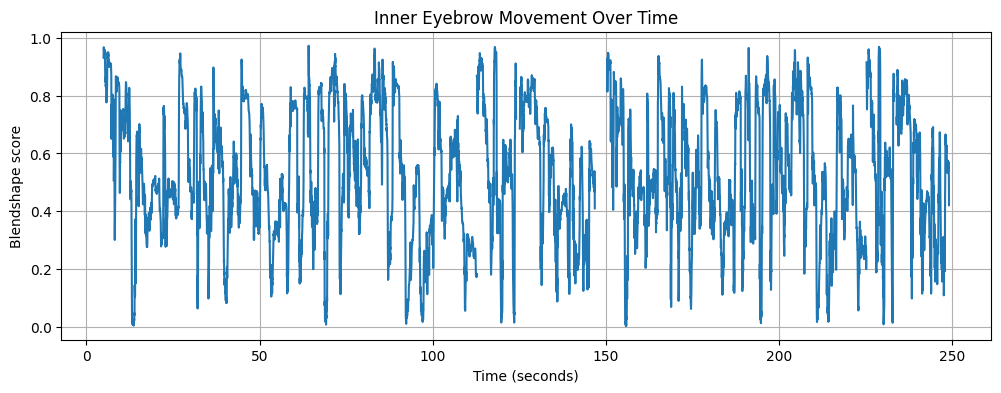

In [ ]:
column = "blendshape_browInnerUp"

if column in df.columns:
    plt.figure(figsize=(12, 4))

    plt.plot(
        df["timestamp_ms"] / 1000,
        df[column]
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Blendshape score")
    plt.title("Inner Eyebrow Movement Over Time")
    plt.grid(True)
    plt.show()
else:
    print("Blendshape column not found.")

In [ ]:
print([
    col for col in df.columns
    if "blendshape_" in col
])

['blendshape__neutral', 'blendshape_browDownLeft', 'blendshape_browDownRight', 'blendshape_browInnerUp', 'blendshape_browOuterUpLeft', 'blendshape_browOuterUpRight', 'blendshape_cheekPuff', 'blendshape_cheekSquintLeft', 'blendshape_cheekSquintRight', 'blendshape_eyeBlinkLeft', 'blendshape_eyeBlinkRight', 'blendshape_eyeLookDownLeft', 'blendshape_eyeLookDownRight', 'blendshape_eyeLookInLeft', 'blendshape_eyeLookInRight', 'blendshape_eyeLookOutLeft', 'blendshape_eyeLookOutRight', 'blendshape_eyeLookUpLeft', 'blendshape_eyeLookUpRight', 'blendshape_eyeSquintLeft', 'blendshape_eyeSquintRight', 'blendshape_eyeWideLeft', 'blendshape_eyeWideRight', 'blendshape_jawForward', 'blendshape_jawLeft', 'blendshape_jawOpen', 'blendshape_jawRight', 'blendshape_mouthClose', 'blendshape_mouthDimpleLeft', 'blendshape_mouthDimpleRight', 'blendshape_mouthFrownLeft', 'blendshape_mouthFrownRight', 'blendshape_mouthFunnel', 'blendshape_mouthLeft', 'blendshape_mouthLowerDownLeft', 'blendshape_mouthLowerDownRigh

In [ ]:
df.to_csv("facial_features.csv", index=False)

df.to_numpy().shape

print("Facial features saved!")

Facial features saved!


In [ ]:
files.download("facial_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Total frames:", len(df))

print("\nDetection counts:")
print(df["face_detected"].value_counts())

print("\nDetection rate:")
print(df["face_detected"].mean() * 100)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

Total frames: 7582

Detection counts:
face_detected
True     7160
False     422
Name: count, dtype: int64

Detection rate:
94.43418623054603

Missing values:
blendshape_noseSneerRight       422
blendshape_noseSneerLeft        422
blendshape_mouthUpperUpRight    422
blendshape_mouthUpperUpLeft     422
landmark_0_x                    422
landmark_0_y                    422
landmark_0_z                    422
landmark_1_x                    422
landmark_1_y                    422
landmark_1_z                    422
dtype: int64


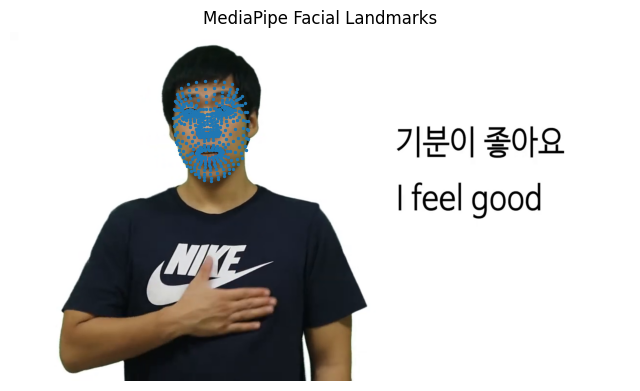

In [ ]:
cap = cv2.VideoCapture(video_path)

# Select a frame where a face was detected
valid_frame = df[df["face_detected"] == True].iloc[50]
frame_number = int(valid_frame["frame"])

cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
success, frame = cap.read()

cap.release()

if success:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(rgb)

    landmarks = [
        (valid_frame[f"landmark_{i}_x"],
         valid_frame[f"landmark_{i}_y"])
        for i in range(478)
    ]

    height, width = rgb.shape[:2]

    x = [p[0] * width for p in landmarks]
    y = [p[1] * height for p in landmarks]

    plt.scatter(x, y, s=2)
    plt.title("MediaPipe Facial Landmarks")
    plt.axis("off")
    plt.show()

In [ ]:
blendshape_columns = [
    col for col in df.columns
    if col.startswith("blendshape_")
]

print("Number of blendshape features:", len(blendshape_columns))

for col in blendshape_columns:
    print(col)

Number of blendshape features: 52
blendshape__neutral
blendshape_browDownLeft
blendshape_browDownRight
blendshape_browInnerUp
blendshape_browOuterUpLeft
blendshape_browOuterUpRight
blendshape_cheekPuff
blendshape_cheekSquintLeft
blendshape_cheekSquintRight
blendshape_eyeBlinkLeft
blendshape_eyeBlinkRight
blendshape_eyeLookDownLeft
blendshape_eyeLookDownRight
blendshape_eyeLookInLeft
blendshape_eyeLookInRight
blendshape_eyeLookOutLeft
blendshape_eyeLookOutRight
blendshape_eyeLookUpLeft
blendshape_eyeLookUpRight
blendshape_eyeSquintLeft
blendshape_eyeSquintRight
blendshape_eyeWideLeft
blendshape_eyeWideRight
blendshape_jawForward
blendshape_jawLeft
blendshape_jawOpen
blendshape_jawRight
blendshape_mouthClose
blendshape_mouthDimpleLeft
blendshape_mouthDimpleRight
blendshape_mouthFrownLeft
blendshape_mouthFrownRight
blendshape_mouthFunnel
blendshape_mouthLeft
blendshape_mouthLowerDownLeft
blendshape_mouthLowerDownRight
blendshape_mouthPressLeft
blendshape_mouthPressRight
blendshape_mouthPu

In [ ]:
selected_features = [
    # Eyebrows
    "blendshape_browInnerUp",
    "blendshape_browDownLeft",
    "blendshape_browDownRight",
    "blendshape_browOuterUpLeft",
    "blendshape_browOuterUpRight",

    # Eyes
    "blendshape_eyeBlinkLeft",
    "blendshape_eyeBlinkRight",
    "blendshape_eyeWideLeft",
    "blendshape_eyeWideRight",
    "blendshape_eyeSquintLeft",
    "blendshape_eyeSquintRight",

    # Mouth
    "blendshape_jawOpen",
    "blendshape_mouthFunnel",
    "blendshape_mouthPucker",
    "blendshape_mouthSmileLeft",
    "blendshape_mouthSmileRight",
    "blendshape_mouthPressLeft",
    "blendshape_mouthPressRight"
]

facial_df = df[
    ["frame", "timestamp_ms", "face_detected"]
    + selected_features
].copy()

print("Selected feature shape:", facial_df.shape)

facial_df.head()

Selected feature shape: (7582, 21)


,frame,timestamp_ms,face_detected,blendshape_browInnerUp,blendshape_browDownLeft,blendshape_browDownRight,blendshape_browOuterUpLeft,blendshape_browOuterUpRight,blendshape_eyeBlinkLeft,blendshape_eyeBlinkRight,...,blendshape_eyeWideRight,blendshape_eyeSquintLeft,blendshape_eyeSquintRight,blendshape_jawOpen,blendshape_mouthFunnel,blendshape_mouthPucker,blendshape_mouthSmileLeft,blendshape_mouthSmileRight,blendshape_mouthPressLeft,blendshape_mouthPressRight
0,0,0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,33,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,66,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,100,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,133,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


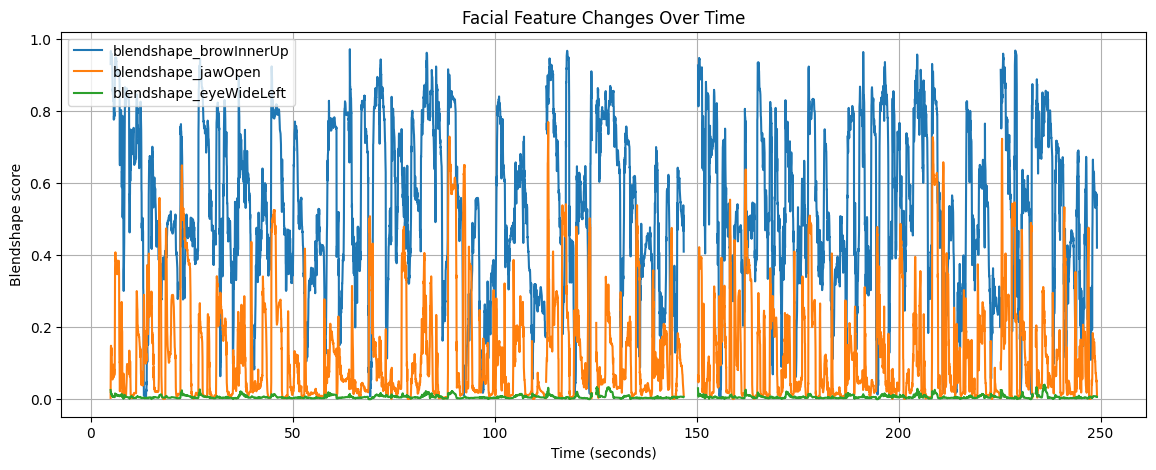

In [ ]:
plt.figure(figsize=(14, 5))

for feature in [
    "blendshape_browInnerUp",
    "blendshape_jawOpen",
    "blendshape_eyeWideLeft"
]:
    plt.plot(
        facial_df["timestamp_ms"] / 1000,
        facial_df[feature],
        label=feature
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Blendshape score")
plt.title("Facial Feature Changes Over Time")
plt.legend()
plt.grid()
plt.show()

In [ ]:
facial_df.to_csv(
    "selected_facial_features.csv",
    index=False
)

print("Saved selected facial features!")

Saved selected facial features!


# Extract Temporal Features

In [ ]:
temporal_df = facial_df.copy()

feature_columns = [
    col for col in temporal_df.columns
    if col.startswith("blendshape_")
]

print("Number of features:", len(feature_columns))

Number of features: 18


In [ ]:
# Calculate time difference in seconds
time_diff = temporal_df["timestamp_ms"].diff() / 1000

for col in feature_columns:
    temporal_df[f"{col}_delta"] = (
        temporal_df[col].diff() / time_diff
    )

print(temporal_df.head())

   frame  timestamp_ms  face_detected  blendshape_browInnerUp  \
0      0             0          False                     NaN   
1      1            33          False                     NaN   
2      2            66          False                     NaN   
3      3           100          False                     NaN   
4      4           133          False                     NaN   

   blendshape_browDownLeft  blendshape_browDownRight  \
0                      NaN                       NaN   
1                      NaN                       NaN   
2                      NaN                       NaN   
3                      NaN                       NaN   
4                      NaN                       NaN   

   blendshape_browOuterUpLeft  blendshape_browOuterUpRight  \
0                         NaN                          NaN   
1                         NaN                          NaN   
2                         NaN                          NaN   
3                       

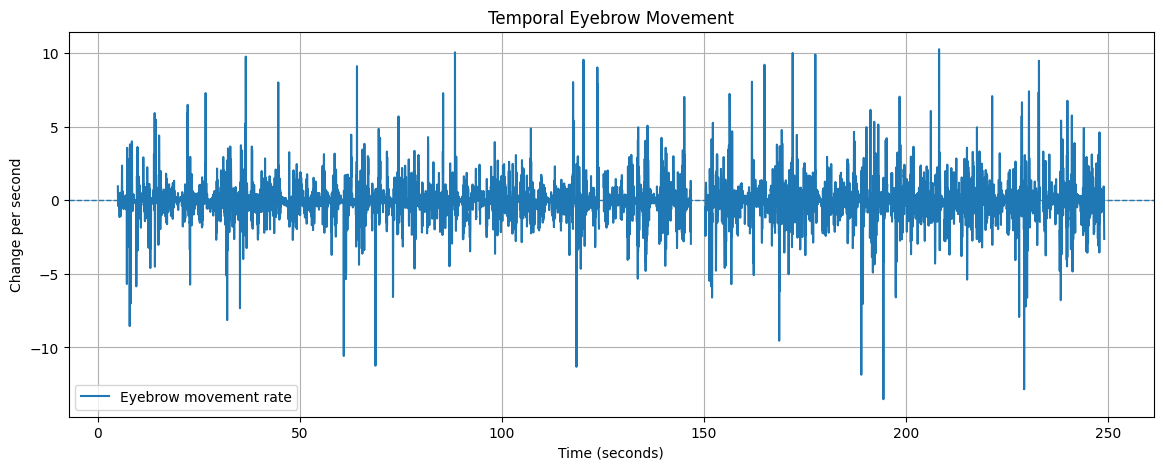

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    temporal_df["timestamp_ms"] / 1000,
    temporal_df["blendshape_browInnerUp_delta"],
    label="Eyebrow movement rate"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Time (seconds)")
plt.ylabel("Change per second")
plt.title("Temporal Eyebrow Movement")
plt.legend()
plt.grid()
plt.show()

In [ ]:
temporal_df.to_csv(
    "temporal_facial_features.csv",
    index=False
)

print("Temporal features saved!")

Temporal features saved!


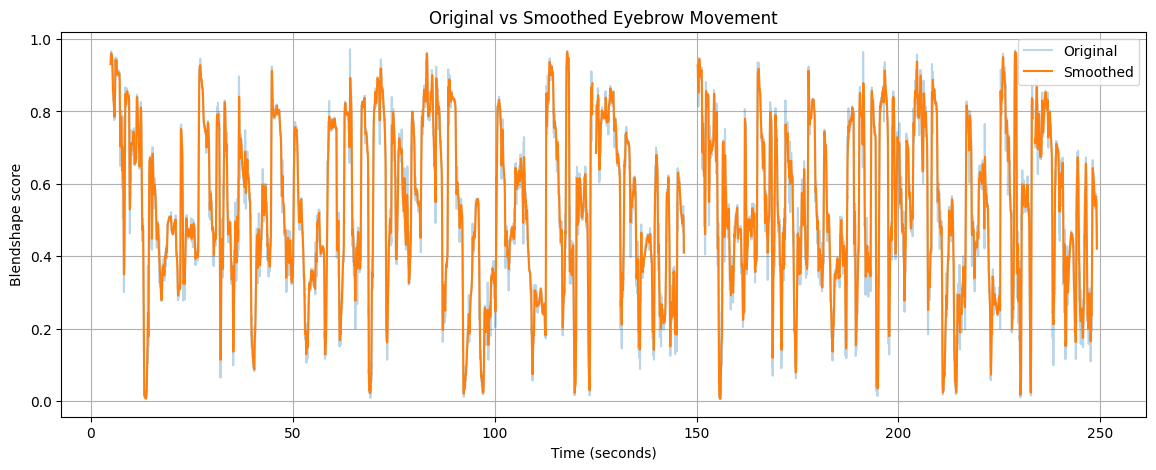

In [ ]:
# Smooth eyebrow movement using a 5-frame rolling average

temporal_df["browInnerUp_smoothed"] = (
    temporal_df["blendshape_browInnerUp"]
    .rolling(window=5, center=True, min_periods=1)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    temporal_df["timestamp_ms"] / 1000,
    temporal_df["blendshape_browInnerUp"],
    alpha=0.3,
    label="Original"
)

plt.plot(
    temporal_df["timestamp_ms"] / 1000,
    temporal_df["browInnerUp_smoothed"],
    label="Smoothed"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Blendshape score")
plt.title("Original vs Smoothed Eyebrow Movement")
plt.legend()
plt.grid()
plt.show()

In [ ]:
print("Missing face frames:",
      (~temporal_df["face_detected"]).sum())

print("Missing eyebrow values:",
      temporal_df["blendshape_browInnerUp"].isna().sum())

Missing face frames: 422
Missing eyebrow values: 422


# Build Facial Feature Sequence

In [ ]:
feature_columns = [
    col for col in facial_df.columns
    if col.startswith("blendshape_")
]

X_face = facial_df[feature_columns].to_numpy()

print("Facial sequence shape:", X_face.shape)

Facial sequence shape: (7582, 18)


In [ ]:
X_face_df = pd.DataFrame(X_face, columns=feature_columns)

# Interpolate short gaps only
X_face_df = X_face_df.interpolate(
    method="linear",
    limit=5,
    limit_area="inside"
)

# Fill remaining missing values with zero
# The face mask will tell the model these frames were unavailable
X_face_df = X_face_df.fillna(0)

X_face = X_face_df.to_numpy(dtype=np.float32)

print("Missing values:", np.isnan(X_face).sum())
print("Sequence shape:", X_face.shape)

Missing values: 0
Sequence shape: (7582, 18)


In [ ]:
face_mask = facial_df["face_detected"].to_numpy(dtype=np.float32)

print("Face mask shape:", face_mask.shape)
print("Detected frames:", int(face_mask.sum()))

Face mask shape: (7582,)
Detected frames: 7160


In [ ]:
X_face = np.clip(X_face, 0, 1)

print("Minimum:", X_face.min())
print("Maximum:", X_face.max())

Minimum: 0.0
Maximum: 0.9984817


In [ ]:
np.save("X_face.npy", X_face)
np.save("face_mask.npy", face_mask)

print("Saved successfully!")

Saved successfully!


In [ ]:
files.download("X_face.npy")
files.download("face_mask.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Final facial sequence:", X_face.shape)
print("Final face mask:", face_mask.shape)
print("Data type:", X_face.dtype)

Final facial sequence: (7582, 18)
Final face mask: (7582,)
Data type: float32
